# Class distributions in the experimental splits

This notebook describes the class distributions in the saved experimental partitions. Training sizes include any internal validation data; the held-out test set is shared across training sizes and models. Smaller training sets are nested within larger ones, so their observations must not be added together.

Counts represent **dataset rows**, not necessarily unique patients. In particular, the stored row indices do not establish whether Diabetes-130 contains repeated visits from the same patient. The notebook reads trusted pickle files and does not modify the data or results.

In [1]:
from pathlib import Path
import pickle
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

DATASETS = ['heart', 'diabetes_h', 'diabetes_130', 'obesity', 'obesity_bin', 'breast_cancer']
DATASET_LABELS = {'heart': 'Heart', 'diabetes_h': 'Diabetes-H', 'diabetes_130': 'Diabetes-130',
                  'obesity': 'Obesity', 'obesity_bin': 'Obesity-Bin', 'breast_cancer': 'Breast Cancer'}
CLASS_COLORS = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9', '#7B3294']
FIGURE_SIZE = (17, 10)
FONT_SIZE = 12

cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in (cwd, *cwd.parents) if (p / 'src' / 'data.py').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open this notebook within the project directory.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data import load_data
from src.utils import get_config

args = get_config('performance')
RESULTS_DIR = PROJECT_ROOT / 'results_metrics' / 'current'
print(f'Reading saved splits from: {RESULTS_DIR}')

C:\Users\Alex\CODE\classification_with_kans\src\models\nam\trainer\trainer.py:8: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm


Reading saved splits from: C:\Users\Alex\CODE\classification_with_kans\results_metrics\current


## Validation of saved partitions

For each dataset and size, the notebook reads every available model result and checks that saved training and test indices agree across models. It also checks that test indices are identical across sizes, train and test are disjoint, training sets are nested, and saved test labels match the current dataset labels. Missing files and any discrepancies are reported below.

A dataset with inconsistent or unverifiable saved partitions is excluded from the tables and figure, rather than silently choosing one model's split. These checks require the datasets to retain the same row order as during the experiments; matching test labels alone cannot prove that all input rows are unchanged.

In [2]:
def read_indices(result, key, total_rows):
    values = np.asarray(result[key])
    if values.ndim != 1 or not np.issubdtype(values.dtype, np.integer):
        raise ValueError(f'{key} must be a one-dimensional array of integer row indices')
    if len(np.unique(values)) != len(values):
        raise ValueError(f'{key} contains duplicate indices')
    if np.any(values < 0) or np.any(values >= total_rows):
        raise ValueError(f'{key} contains out-of-range indices')
    return values.astype(int, copy=False)


def inspect_dataset(dataset):
    _, labels = load_data(dataset, args, raw=True)
    labels = labels.reset_index(drop=True)
    sizes = sorted(args['dataset_sizes'][dataset])
    models = args['models']
    issues, splits = [], {}
    fixed_test = None
    verified = True

    for size in sizes:
        baseline = None
        for model in models:
            path = RESULTS_DIR / str(size) / dataset / f'{model}.pkl'
            if not path.is_file():
                issues.append((dataset, size, model, 'Missing result file', str(path)))
                continue
            try:
                with path.open('rb') as file:
                    result = pickle.load(file)
                if not isinstance(result, dict):
                    raise ValueError('Expected a result dictionary')
                expected = {'dataset': dataset, 'train_size': size, 'model': model}
                if any(result.get(k) != value for k, value in expected.items()):
                    raise ValueError('Result metadata does not match its path')
                train = read_indices(result, 'train_indices', len(labels))
                test = read_indices(result, 'test_indices', len(labels))
                if len(train) != size:
                    raise ValueError(f'Expected {size} training rows, found {len(train)}')
                if np.intersect1d(train, test).size:
                    raise ValueError('Training and test rows overlap')
                saved_y_test = np.asarray(result['y_test']).reshape(-1)
                if not np.array_equal(labels.iloc[test].to_numpy(), saved_y_test):
                    raise ValueError('Saved test labels do not match current data and indices')
                if baseline is not None and (not np.array_equal(train, baseline[0]) or not np.array_equal(test, baseline[1])):
                    raise ValueError('Saved indices differ from another model for this size')
                if baseline is None:
                    baseline = (train, test)
            except Exception as exc:
                verified = False
                issues.append((dataset, size, model, str(exc), str(path)))
        if baseline is None:
            verified = False
            issues.append((dataset, size, '—', 'No valid result available for this size', ''))
            continue
        train, test = baseline
        if fixed_test is not None and not np.array_equal(test, fixed_test):
            verified = False
            issues.append((dataset, size, '—', 'Test indices differ across sizes', ''))
        else:
            fixed_test = test
        splits[size] = train

    for smaller, larger in zip(sizes, sizes[1:]):
        if smaller in splits and larger in splits and not np.isin(splits[smaller], splits[larger]).all():
            verified = False
            issues.append((dataset, smaller, '—', f'Training rows are not nested in size {larger}', ''))

    return {'labels': labels, 'splits': splits, 'test': fixed_test, 'verified': verified}, issues


datasets, all_issues = {}, []
for dataset in DATASETS:
    try:
        datasets[dataset], issues = inspect_dataset(dataset)
        all_issues.extend(issues)
    except Exception as exc:
        all_issues.append((dataset, '—', '—', f'Could not load dataset: {exc}', ''))

issue_table = pd.DataFrame(all_issues, columns=['Dataset', 'Training size', 'Model', 'Issue', 'File'])
summary = pd.DataFrame([
    {'Dataset': DATASET_LABELS.get(name, name),
     'Valid saved sizes': len(info['splits']),
     'Expected sizes': len(args['dataset_sizes'][name]),
     'Partition checks': 'Passed' if info['verified'] else 'Failed'}
    for name, info in datasets.items()
])
display(summary)
if issue_table.empty:
    print('No missing files or partition inconsistencies detected.')
else:
    display(issue_table)

,Dataset,Valid saved sizes,Expected sizes,Partition checks
0,Heart,5,5,Passed
1,Diabetes-H,5,5,Passed
2,Diabetes-130,5,5,Passed
3,Obesity,4,4,Passed
4,Obesity-Bin,4,4,Passed
5,Breast Cancer,2,2,Passed


No missing files or partition inconsistencies detected.


## Tables: counts and percentages by class

Each cell gives the number of rows and the percentage within that split. The `Test` row is the same held-out set for every training size. Class labels are the encoded values used in the experiments. Missing model files are reported above; a table can still be shown if at least one saved result for every size passes the checks and all available results agree.

In [3]:
def class_table(dataset):
    info = datasets.get(dataset)
    if info is None or not info['verified']:
        raise ValueError(f'{dataset}: saved partitions failed validation or could not be loaded')
    labels = info['labels']
    classes = sorted(labels.unique().tolist())
    rows = []
    partitions = [(f'Train + validation, N={size}', indices)
                  for size, indices in sorted(info['splits'].items())]
    partitions.append(('Test', info['test']))
    for split_name, indices in partitions:
        counts = labels.iloc[indices].value_counts().reindex(classes, fill_value=0)
        total = len(indices)
        if int(counts.sum()) != total:
            raise ValueError(f'{dataset}: class counts do not sum to the split size')
        row = {'Split': split_name, 'Total': total}
        for cls in classes:
            count = int(counts.loc[cls])
            row[f'Class {cls}, n (%)'] = f'{count} ({100 * count / total:.1f}%)'
        rows.append(row)
    return pd.DataFrame(rows)


def show_dataset_table(dataset):
    if dataset not in DATASETS:
        print('Dataset not selected.')
    elif dataset not in datasets or not datasets[dataset]['verified']:
        print('Table unavailable: inspect the validation diagnostics above.')
    else:
        display(class_table(dataset))

##### Heart — class distribution

Counts and percentages refer to each train + validation split and the fixed test set.

In [4]:
show_dataset_table('heart')

,Split,Total,"Class 0, n (%)","Class 1, n (%)"
0,"Train + validation, N=100",100,91 (91.0%),9 (9.0%)
1,"Train + validation, N=500",500,453 (90.6%),47 (9.4%)
2,"Train + validation, N=1000",1000,906 (90.6%),94 (9.4%)
3,"Train + validation, N=5000",5000,4529 (90.6%),471 (9.4%)
4,"Train + validation, N=10000",10000,9058 (90.6%),942 (9.4%)
5,Test,2500,2265 (90.6%),235 (9.4%)


##### Diabetes-H — class distribution

Counts and percentages refer to each train + validation split and the fixed test set.

In [5]:
show_dataset_table('diabetes_h')

,Split,Total,"Class 0, n (%)","Class 1, n (%)","Class 2, n (%)"
0,"Train + validation, N=100",100,84 (84.0%),2 (2.0%),14 (14.0%)
1,"Train + validation, N=500",500,421 (84.2%),9 (1.8%),70 (14.0%)
2,"Train + validation, N=1000",1000,843 (84.3%),18 (1.8%),139 (13.9%)
3,"Train + validation, N=5000",5000,4212 (84.2%),91 (1.8%),697 (13.9%)
4,"Train + validation, N=10000",10000,8424 (84.2%),182 (1.8%),1394 (13.9%)
5,Test,2500,2106 (84.2%),46 (1.8%),348 (13.9%)


##### Diabetes-130 — class distribution

Counts and percentages refer to each train + validation split and the fixed test set.

In [6]:
show_dataset_table('diabetes_130')

,Split,Total,"Class 0, n (%)","Class 1, n (%)","Class 2, n (%)"
0,"Train + validation, N=100",100,54 (54.0%),35 (35.0%),11 (11.0%)
1,"Train + validation, N=500",500,268 (53.6%),176 (35.2%),56 (11.2%)
2,"Train + validation, N=1000",1000,536 (53.6%),352 (35.2%),112 (11.2%)
3,"Train + validation, N=5000",5000,2683 (53.7%),1758 (35.2%),559 (11.2%)
4,"Train + validation, N=10000",10000,5367 (53.7%),3515 (35.1%),1118 (11.2%)
5,Test,2500,1342 (53.7%),879 (35.2%),279 (11.2%)


##### Obesity — class distribution

Counts and percentages refer to each train + validation split and the fixed test set.

In [7]:
show_dataset_table('obesity')

,Split,Total,"Class 0, n (%)","Class 1, n (%)","Class 2, n (%)","Class 3, n (%)","Class 4, n (%)","Class 5, n (%)","Class 6, n (%)"
0,"Train + validation, N=100",100,13 (13.0%),14 (14.0%),13 (13.0%),14 (14.0%),17 (17.0%),14 (14.0%),15 (15.0%)
1,"Train + validation, N=500",500,64 (12.8%),68 (13.6%),68 (13.6%),69 (13.8%),84 (16.8%),70 (14.0%),77 (15.4%)
2,"Train + validation, N=1000",1000,129 (12.9%),136 (13.6%),137 (13.7%),138 (13.8%),167 (16.7%),140 (14.0%),153 (15.3%)
3,"Train + validation, N=1688",1688,218 (12.9%),229 (13.6%),232 (13.7%),232 (13.7%),281 (16.6%),237 (14.0%),259 (15.3%)
4,Test,423,54 (12.8%),58 (13.7%),58 (13.7%),58 (13.7%),70 (16.5%),60 (14.2%),65 (15.4%)


##### Obesity-Bin — class distribution

Counts and percentages refer to each train + validation split and the fixed test set.

In [8]:
show_dataset_table('obesity_bin')

,Split,Total,"Class 0, n (%)","Class 1, n (%)"
0,"Train + validation, N=100",100,54 (54.0%),46 (46.0%)
1,"Train + validation, N=500",500,270 (54.0%),230 (46.0%)
2,"Train + validation, N=1000",1000,540 (54.0%),460 (46.0%)
3,"Train + validation, N=1688",1688,911 (54.0%),777 (46.0%)
4,Test,423,228 (53.9%),195 (46.1%)


##### Breast Cancer — class distribution

Counts and percentages refer to each train + validation split and the fixed test set.

In [9]:
show_dataset_table('breast_cancer')

,Split,Total,"Class 0, n (%)","Class 1, n (%)"
0,"Train + validation, N=100",100,37 (37.0%),63 (63.0%)
1,"Train + validation, N=455",455,170 (37.4%),285 (62.6%)
2,Test,114,42 (36.8%),72 (63.2%)


## Class counts across training sizes and test

Each panel represents one dataset. The horizontal axis contains that dataset's available training sizes, followed by its fixed test set; grouped bars denote classes. The vertical axis is the number of rows, with a separate scale for each dataset. Classes with the same encoded label can have different meanings across datasets. Small training sizes may look small next to the largest sizes because the bars show absolute counts.

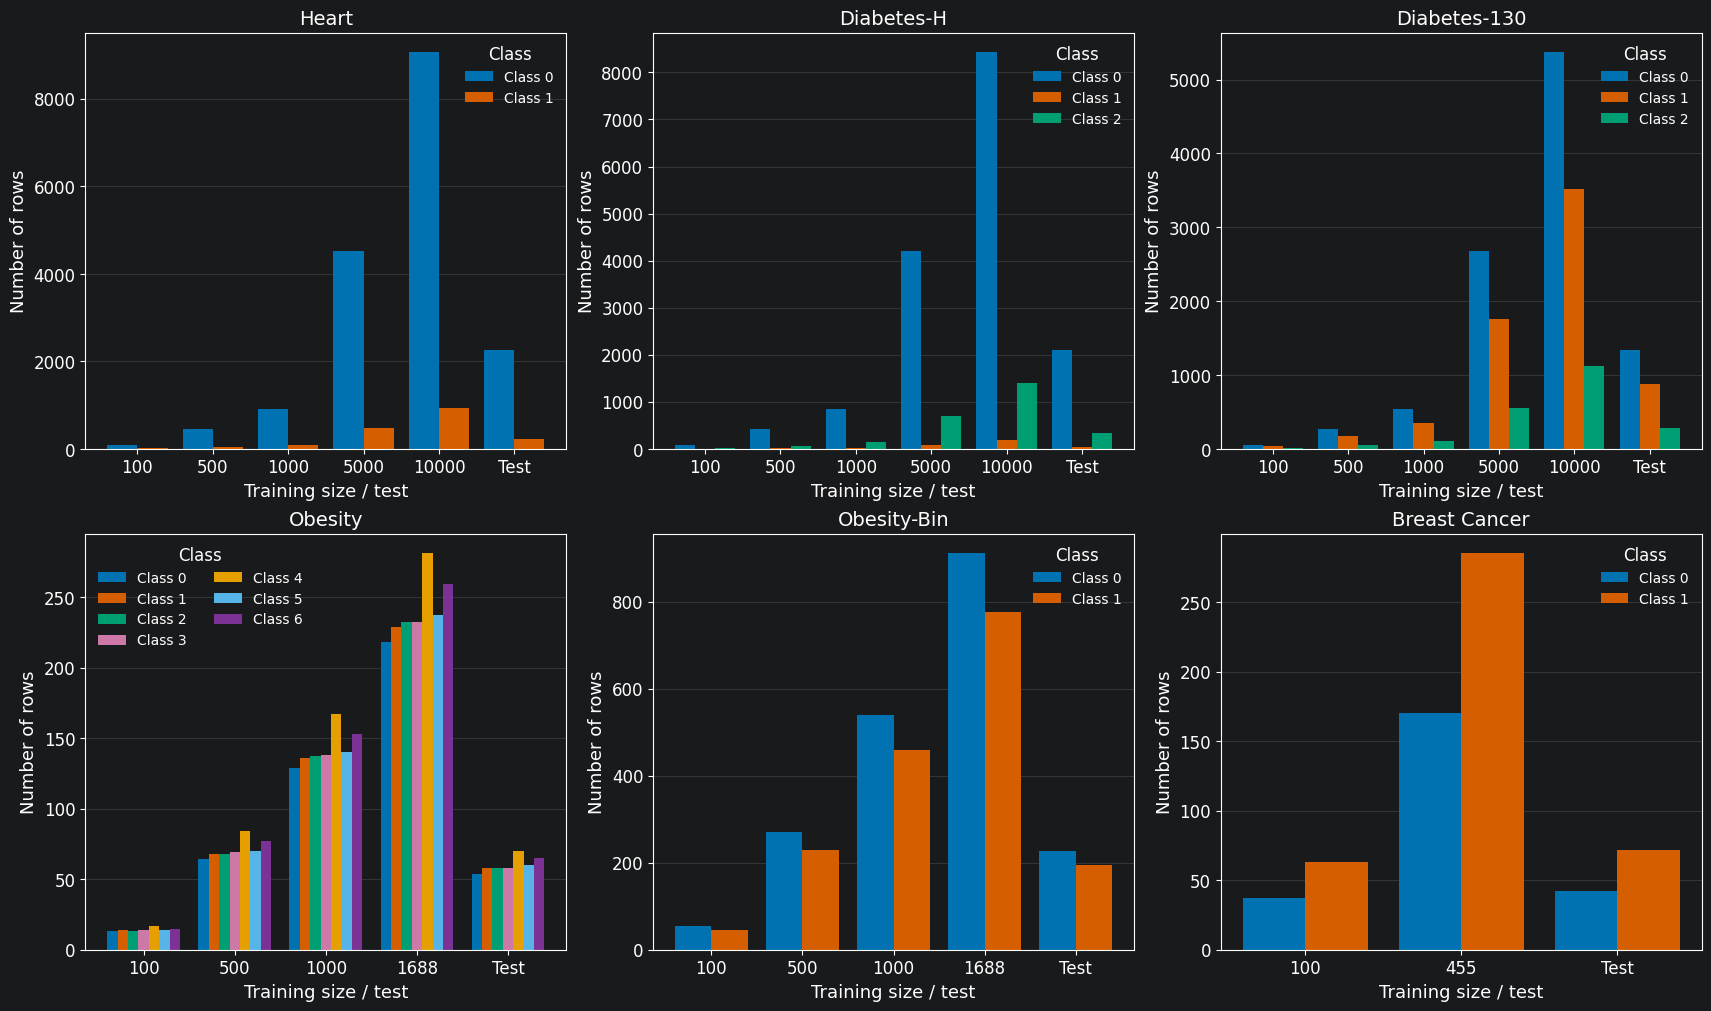

In [10]:
plt.rcParams.update({'font.size': FONT_SIZE, 'axes.titlesize': FONT_SIZE + 2,
                     'axes.labelsize': FONT_SIZE + 1, 'xtick.labelsize': FONT_SIZE,
                     'ytick.labelsize': FONT_SIZE, 'legend.fontsize': FONT_SIZE - 2})
fig, axes = plt.subplots(2, 3, figsize=FIGURE_SIZE, constrained_layout=True)

for ax, dataset in zip(axes.flat, DATASETS):
    info = datasets.get(dataset)
    ax.set_title(DATASET_LABELS.get(dataset, dataset))
    if info is None or not info['verified']:
        ax.text(0.5, 0.5, 'Partition checks failed\nSee diagnostics',
                ha='center', va='center', transform=ax.transAxes)
        ax.set_axis_off()
        continue
    labels = info['labels']
    classes = sorted(labels.unique().tolist())
    if len(classes) > len(CLASS_COLORS):
        raise ValueError(f'Add colors for {dataset}: {len(classes)} classes found')
    partitions = [(str(size), indices) for size, indices in sorted(info['splits'].items())]
    partitions.append(('Test', info['test']))
    positions = np.arange(len(partitions))
    width = 0.8 / len(classes)
    for index, cls in enumerate(classes):
        counts = [int((labels.iloc[indices] == cls).sum()) for _, indices in partitions]
        offset = (index - (len(classes) - 1) / 2) * width
        ax.bar(positions + offset, counts, width=width, color=CLASS_COLORS[index], label=f'Class {cls}')
    ax.set_xticks(positions, [name for name, _ in partitions])
    ax.set_xlabel('Training size / test')
    ax.set_ylabel('Number of rows')
    ax.grid(axis='y', alpha=0.25)
    ax.set_axisbelow(True)
    ax.legend(title='Class', frameon=False, ncol=2 if len(classes) > 4 else 1)

for ax in list(axes.flat)[len(DATASETS):]:
    ax.set_visible(False)

plt.show()
# To export manually, run e.g. fig.savefig('class_distributions.pdf', bbox_inches='tight')

## Interpretation

The training partitions are selected with stratification, so class proportions are approximately preserved; exact proportions may vary because counts are integers. Nested sets share observations. The test bars describe one fixed hold-out per dataset, rather than an additional training size. These tables describe observed rows and do not establish independence or count unique patients.